# R1 v2 — Leakage-Aware Spectral–Spatial Benchmark for Cholangiocarcinoma Microscopic HSI

**Dataset:** Multidimensional Choledoch Database (Kaggle: `ethelzq/multidimensional-choledoch-database`), classes **L / N / P**.

**What changed vs. v1 (and why)**

| v1 problem | v2 fix |
|---|---|
| `.hdr` and `.raw` of the same cube both used as separate scenes (40 duplicates) | Only ENVI `.hdr` headers are scenes; duplicates removed by name **and** content hash |
| 48 `*-blank` background reference cubes used as tissue | Blank / reference cubes excluded |
| `MAX_PATCHES_TOTAL` stopped after 300 of 964 scenes | All usable scenes used; per-class patches-per-scene for balance |
| Whole 150 MB cube loaded per scene | Windowed memmap reads (only the patch + a strided sample for normalisation) |
| No imbalance handling → model predicted only class L | Class-balanced loss weights, flip/rotate augmentation, early stopping on **validation macro-F1** |
| One split, one seed, one model | 5-fold CV under 3 split protocols × 3 classical + 4 deep models, majority baseline |
| Accuracy only | Acc, balanced acc, macro P/R/F1, per-class F1, κ, MCC, macro AUC, scene-level metrics, patient-cluster bootstrap CIs, paired tests |

**Split protocols (increasing strictness)**
- **E1 PatchWise** – random stratified patch split (patches from the same image in train and test) → maximal leakage
- **E2 ImageWise** – grouped by scene (no image shared, but the same patient can be in train and test)
- **E3 PatientWise** – grouped by patient (`StratifiedGroupKFold`) → leakage-free, **primary result**

Runtime on Kaggle 2×T4: roughly 3–5 h with defaults. Runs are checkpointed in `runs/`, so re-running the training cell resumes where it stopped.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/050541_2-20x-blank.raw
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/031193b-20x-blank.hdr
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/041602-20x-roi7.raw
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/055380-20x-roi5.hdr
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/045073-20x-roi5.hdr
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/031541-20x-roi3.hdr
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/045073-20x-roi10.raw
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/040037-20x-roi6.hdr
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/050028-20x-blank.raw
/kaggle/input/datasets/ethelzq/multidimensional-choledoch-database/N/N/hyper/031541vtc-20x-roi2.raw
/kaggle/input/datase

In [2]:
# =====================================================================
# 0. SETUP & CONFIGURATION
# =====================================================================
import os, re, gc, json, time, random, hashlib, warnings, subprocess, sys, shutil
from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, cohen_kappa_score, matthews_corrcoef,
                             roc_auc_score, roc_curve, auc)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from scipy import stats

try:
    import spectral
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "spectral"], check=True)
    import spectral
spectral.settings.envi_support_nonlowercase_params = True

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s)
    try:
        import tensorflow as tf; tf.random.set_seed(s)
    except Exception:
        pass
set_seed(SEED)

# ---------------- paths ----------------
KAGGLE_INPUT = Path(os.environ.get("HSI_INPUT", "/kaggle/input"))
OUT_BASE = Path(os.environ.get("HSI_OUT", "/kaggle/working/R1v2_Leakage_Aware_HSI"))

# ---------------- data ----------------
CLASSES = ["L", "N", "P"]
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
PATCH = 25                      # spatial patch size (odd)
N_BANDS = 32                    # bands kept by uniform spectral sampling
# more patches from minority-class scenes -> roughly balanced patch counts
PATCHES_PER_SCENE = {"L": 20, "N": 48, "P": 48}
# "global": one per-band 1-99 percentile scaling for the whole dataset (keeps absolute spectral differences)
# "scene" : per-scene percentile scaling (removes illumination drift but also absolute class differences)
# "blank" : flat-field by the same patient's *-blank reference cube, then global scaling (ablation)
NORM_MODE = os.environ.get("HSI_NORM", "global")
NORM_STRIDE = 16                # spatial stride for normalisation samples
NORM_SCENES = 80                # scenes sampled to estimate global percentiles
BG_MEAN_MAX = 0.92              # reject near-white background patches (normalised mean)
MIN_PATCH_STD = 0.02            # reject flat patches
EXCLUDE_PATTERNS = ["blank"]    # background/reference cubes, not tissue

# ---------------- experiment ----------------
# QUICK_TEST=True: ~5-10 min sanity run (few scenes, 3 folds, 2 epochs). Set False for the paper run.
QUICK_TEST = False or os.environ.get("HSI_QUICK", "0") == "1"   # <- set True for the sanity run
N_FOLDS = int(os.environ.get("HSI_FOLDS", 5))
EXPERIMENTS = ["E1_PatchWise", "E2_ImageWise", "E3_PatientWise"]
ML_MODELS = ["LogReg", "SVM_RBF", "RandomForest"]
DL_MODELS = ["CNN2D", "CNN3D", "HybridSN", "SpecTransformer"]
RUN_DL = os.environ.get("HSI_RUN_DL", "1") == "1"
BATCH = 64
EPOCHS = 40
PATIENCE = 8
LR = 1e-3
SVM_MAX_TRAIN = 12000           # SVM is O(n^2); subsample the training fold if larger
if QUICK_TEST:
    N_FOLDS, EPOCHS, PATIENCE = 3, 2, 1
    OUT_BASE = OUT_BASE.parent / (OUT_BASE.name + "_QUICK")

OUT = OUT_BASE / f"norm_{NORM_MODE}"     # separate result folder per normalisation mode
(OUT / "runs").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(exist_ok=True)

print("Output:", OUT)
print("Folds:", N_FOLDS, "| Experiments:", EXPERIMENTS)
print("Models:", ML_MODELS + (DL_MODELS if RUN_DL else []))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.2/215.2 kB 3.2 MB/s eta 0:00:00
Output: /kaggle/working/R1v2_Leakage_Aware_HSI/norm_global
Folds: 5 | Experiments: ['E1_PatchWise', 'E2_ImageWise', 'E3_PatientWise']
Models: ['LogReg', 'SVM_RBF', 'RandomForest', 'CNN2D', 'CNN3D', 'HybridSN', 'SpecTransformer']


In [3]:
# =====================================================================
# 1. DISCOVER & CLEAN SCENES
# =====================================================================
def find_data_root():
    cands = [p for p in KAGGLE_INPUT.rglob("*") if p.is_dir() and "choledoch" in p.name.lower()]
    if cands:
        return min(cands, key=lambda p: len(p.parts))
    return KAGGLE_INPUT

DATA_ROOT = Path(os.environ.get("HSI_DATA_ROOT", find_data_root()))
print("DATA_ROOT:", DATA_ROOT)

def infer_label(path):
    for part in reversed([x.upper() for x in path.parts[:-1]]):
        if part in CLASSES:
            return part
    return None

def infer_patient(stem):
    # file names look like 034004a2-20x-roi2, 042477_2-20x-roi5 -> leading digit run = patient/case id
    m = re.match(r"^(\d+)", stem)
    if m:
        return "PAT_" + m.group(1)
    nums = re.findall(r"\d+", stem)
    return "PAT_" + nums[0] if nums else "PAT_" + stem

def quick_hash(path, nbytes=1 << 20):
    # hash of size + 1 MB taken from the middle of the binary file (cheap content-duplicate check)
    size = os.path.getsize(path)
    h = hashlib.md5(str(size).encode())
    with open(path, "rb") as f:
        f.seek(max(0, size // 2 - nbytes // 2))
        h.update(f.read(nbytes))
    return h.hexdigest()

hdr_files = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() == ".hdr")
print("ENVI headers found:", len(hdr_files))

rows, dropped, blank_refs = [], [], []
for hdr in hdr_files:
    label = infer_label(hdr)
    stem = hdr.stem
    if label is None:
        dropped.append((str(hdr), "no L/N/P folder")); continue
    if any(pat in stem.lower() for pat in EXCLUDE_PATTERNS):
        dropped.append((str(hdr), "blank/reference cube"))
        blank_refs.append(dict(hdr=str(hdr), label=label, patient=infer_patient(stem)))
        continue
    try:
        img = spectral.envi.open(str(hdr))
        data_file = Path(img.filename)
        h, w, b = img.shape
    except Exception as e:
        dropped.append((str(hdr), f"unreadable: {str(e)[:80]}")); continue
    if h < PATCH or w < PATCH or b < 3:
        dropped.append((str(hdr), "too small")); continue
    rows.append(dict(scene_id=f"{label}/{stem}", hdr=str(hdr), data=str(data_file), label=label,
                     patient=infer_patient(stem), height=h, width=w, bands=b,
                     interleave=img.metadata.get("interleave", "?")))

scenes = pd.DataFrame(rows)

# name duplicates
n0 = len(scenes)
dup_name = scenes.duplicated("scene_id")
for _, r in scenes[dup_name].iterrows():
    dropped.append((r.hdr, "duplicate name"))
scenes = scenes[~dup_name]

# content duplicates (identical binary content under different names)
scenes["content_hash"] = [quick_hash(p) for p in scenes["data"]]
dup_content = scenes.duplicated("content_hash")
for _, r in scenes[dup_content].iterrows():
    dropped.append((r.hdr, "duplicate content"))
scenes = scenes[~dup_content].reset_index(drop=True)

dropped_df = pd.DataFrame(dropped, columns=["path", "reason"])
dropped_df.to_csv(OUT / "dropped_scenes.csv", index=False)
scenes.to_csv(OUT / "clean_scenes.csv", index=False)

print("\nDropped:", len(dropped_df)); print(dropped_df.reason.value_counts().to_string())
print("\nClean scenes:", len(scenes))
print(scenes.label.value_counts().to_string())
print("Patients:", scenes.patient.nunique())
print("Patients per class:", scenes.groupby("label").patient.nunique().to_dict())
print("Patients appearing in >1 class:", int((scenes.groupby("patient").label.nunique() > 1).sum()))
print("Bands:", scenes.bands.value_counts().to_dict(), "| interleave:", scenes.interleave.value_counts().to_dict())

if QUICK_TEST:
    # keep up to 8 patients x 3 scenes per class so grouped folds still work
    keep = []
    for c, g in scenes.groupby("label"):
        pats = pd.Series(g.patient.unique()).sample(min(8, g.patient.nunique()), random_state=SEED)
        keep.append(g[g.patient.isin(pats)].groupby("patient").head(3))
    scenes = pd.concat(keep).reset_index(drop=True)
    print("QUICK_TEST subset:", scenes.label.value_counts().to_dict())

blank_refs = pd.DataFrame(blank_refs, columns=["hdr", "label", "patient"])
print("Blank reference cubes available:", len(blank_refs))

dataset_summary = (scenes.groupby("label")
                   .agg(scenes=("scene_id", "count"), patients=("patient", "nunique"))
                   .reindex(CLASSES))
dataset_summary.to_csv(OUT / "dataset_summary.csv")

DATA_ROOT: /kaggle/input/datasets/ethelzq/multidimensional-choledoch-database
ENVI headers found: 645

Dropped: 130
reason
blank/reference cube                                                                            121
unreadable: Unable to determine the ENVI data file name for the given header file. You can s      5
duplicate content                                                                                 4

Clean scenes: 515
label
L    397
N     67
P     51
Patients: 54
Patients per class: {'L': 41, 'N': 20, 'P': 15}
Patients appearing in >1 class: 20
Bands: {60: 515} | interleave: {'bsq': 515}
Blank reference cubes available: 121


In [4]:
# =====================================================================
# 2. PATCH EXTRACTION (windowed memmap reads, per-scene robust normalisation)
# =====================================================================
X_PATH, META_PATH = OUT / f"X_patches_{NORM_MODE}.npy", OUT / f"patch_meta_{NORM_MODE}.csv"

def open_cube(hdr):
    # (rows, cols, bands) view without loading the file into RAM
    return spectral.envi.open(hdr).open_memmap(interleave="bip", writable=False)

BANDS_TOTAL = int(scenes.bands.mode()[0])
BAND_IDX = np.linspace(0, BANDS_TOTAL - 1, min(N_BANDS, BANDS_TOTAL)).round().astype(int)

def strided_sample(hdr):
    mm = open_cube(hdr)
    s = np.asarray(mm[::NORM_STRIDE, ::NORM_STRIDE, :], dtype=np.float32)[:, :, BAND_IDX]
    return np.nan_to_num(s.reshape(-1, len(BAND_IDX)))

def blank_spectrum(row):
    # mean spectrum of the same patient's blank reference (same class folder first, then any folder)
    for cand in (blank_refs[(blank_refs.patient == row.patient) & (blank_refs.label == row.label)],
                 blank_refs[blank_refs.patient == row.patient]):
        if len(cand):
            return np.maximum(strided_sample(cand.hdr.iloc[0]).mean(0), 1e-6)
    return None

def flat_field(row, arr):
    ref = blank_spectrum(row) if NORM_MODE == "blank" else None
    return arr / ref if ref is not None else arr

# label-free global statistics (percentiles only, no labels involved)
GLOBAL_LO = GLOBAL_HI = None
if NORM_MODE in ("global", "blank"):
    pick = scenes.sample(min(NORM_SCENES, len(scenes)), random_state=SEED)
    smp = np.concatenate([flat_field(r, strided_sample(r.hdr)) for r in pick.itertuples()])
    GLOBAL_LO, GLOBAL_HI = np.percentile(smp, 1, axis=0), np.percentile(smp, 99, axis=0)
    del smp
    if NORM_MODE == "blank":
        n_ref = sum(blank_spectrum(r) is not None for r in scenes.itertuples())
        print(f"Flat-field reference found for {n_ref}/{len(scenes)} scenes (others: raw counts)")
print("Normalisation mode:", NORM_MODE)

def scene_patches(row, n_patches, rng):
    mm = open_cube(row.hdr)
    band_idx = BAND_IDX
    if NORM_MODE == "scene":
        sample = strided_sample(row.hdr)
        lo, hi = np.percentile(sample, 1, axis=0), np.percentile(sample, 99, axis=0)
        ref = None
    else:
        lo, hi = GLOBAL_LO, GLOBAL_HI
        ref = blank_spectrum(row) if NORM_MODE == "blank" else None
    scale = np.maximum(hi - lo, 1e-6)

    h, w = mm.shape[:2]
    patches, coords, rejected, attempts = [], [], 0, 0
    while len(patches) < n_patches and attempts < n_patches * 15:
        attempts += 1
        y, x = rng.integers(0, h - PATCH + 1), rng.integers(0, w - PATCH + 1)
        p = np.nan_to_num(np.asarray(mm[y:y + PATCH, x:x + PATCH, :], dtype=np.float32)[:, :, band_idx])
        if ref is not None:
            p = p / ref
        p = np.clip((p - lo) / scale, 0, 1)
        if p.mean() > BG_MEAN_MAX or p.std() < MIN_PATCH_STD:
            rejected += 1; continue
        patches.append(p.astype(np.float16)); coords.append((y, x))
    del mm
    return patches, coords, rejected

if X_PATH.exists() and META_PATH.exists():
    X = np.load(X_PATH)                      # ~1 GB, kept in RAM for fast batching
    meta = pd.read_csv(META_PATH)
    print("Loaded cached patches:", X.shape)
else:
    rng = np.random.default_rng(SEED)
    X_list, meta_rows, rej_total = [], [], 0
    t0 = time.time()
    for i, row in enumerate(scenes.itertuples(), 1):
        try:
            ps, cs, rej = scene_patches(row, PATCHES_PER_SCENE[row.label], rng)
        except Exception as e:
            print("Skipped", row.scene_id, "|", str(e)[:100]); continue
        rej_total += rej
        X_list.extend(ps)
        meta_rows.extend(dict(scene_id=row.scene_id, patient=row.patient, label=row.label, y=y, x=x)
                         for (y, x) in cs)
        if i % 50 == 0:
            print(f"scenes {i}/{len(scenes)} | patches {len(X_list)} | rejected {rej_total} | {time.time()-t0:.0f}s")
    X = np.stack(X_list).astype(np.float16)
    meta = pd.DataFrame(meta_rows)
    np.save(X_PATH, X); meta.to_csv(META_PATH, index=False)
    del X_list; gc.collect()
    print(f"Done in {time.time()-t0:.0f}s, background/flat patches rejected: {rej_total}")

Y = meta.label.map(CLASS_TO_ID).values.astype(np.int32)
GROUPS_PATIENT = meta.patient.values
GROUPS_SCENE = meta.scene_id.values
print("Patch tensor:", X.shape, X.dtype)
print("Patches per class:", dict(Counter(meta.label)))
print("Scenes with patches:", meta.scene_id.nunique(), "| patients:", meta.patient.nunique())

Normalisation mode: global
scenes 50/515 | patches 1000 | rejected 0 | 67s
scenes 100/515 | patches 2000 | rejected 0 | 124s
scenes 150/515 | patches 3000 | rejected 0 | 201s
scenes 200/515 | patches 4000 | rejected 0 | 277s
scenes 250/515 | patches 5000 | rejected 0 | 356s
scenes 350/515 | patches 7000 | rejected 0 | 514s
scenes 400/515 | patches 8084 | rejected 0 | 595s
scenes 450/515 | patches 10484 | rejected 0 | 695s
scenes 500/515 | patches 12884 | rejected 0 | 802s
Done in 840s, background/flat patches rejected: 0
Patch tensor: (13604, 25, 25, 32) float16
Patches per class: {'L': 7940, 'N': 3216, 'P': 2448}
Scenes with patches: 515 | patients: 54


In [5]:
# =====================================================================
# 3. CROSS-VALIDATION FOLDS + LEAKAGE AUDIT
# =====================================================================
def make_folds(exp):
    idx = np.arange(len(Y))
    if exp == "E1_PatchWise":
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
        outer = list(cv.split(idx, Y))
    else:
        groups = GROUPS_SCENE if exp == "E2_ImageWise" else GROUPS_PATIENT
        cv = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
        outer = list(cv.split(idx, Y, groups))
    folds = []
    for k, (trv, te) in enumerate(outer):
        # inner validation split uses the same grouping rule as the outer split
        if exp == "E1_PatchWise":
            tr, va = train_test_split(trv, test_size=0.15, stratify=Y[trv], random_state=SEED + k)
        else:
            g = groups[trv]
            inner = StratifiedGroupKFold(6, shuffle=True, random_state=SEED + k)
            a, b = next(inner.split(trv, Y[trv], g))
            tr, va = trv[a], trv[b]
        folds.append(dict(train=np.sort(tr), val=np.sort(va), test=np.sort(te)))
    return folds

FOLDS = {e: make_folds(e) for e in EXPERIMENTS}

audit = []
for exp, folds in FOLDS.items():
    for k, f in enumerate(folds):
        P = {s: set(GROUPS_PATIENT[f[s]]) for s in f}
        S = {s: set(GROUPS_SCENE[f[s]]) for s in f}
        audit.append(dict(
            experiment=exp, fold=k,
            n_train=len(f["train"]), n_val=len(f["val"]), n_test=len(f["test"]),
            test_class_counts=dict(Counter(np.array(CLASSES)[Y[f["test"]]])),
            train_test_scene_overlap=len(S["train"] & S["test"]),
            train_test_patient_overlap=len(P["train"] & P["test"]),
            train_val_patient_overlap=len(P["train"] & P["val"]),
            test_patients=len(P["test"])))
        np.savez(OUT / "runs" / f"split_{exp}_fold{k}.npz", **f)
audit_df = pd.DataFrame(audit)
audit_df.to_csv(OUT / "leakage_audit.csv", index=False)
print(audit_df.to_string(index=False))

# hard guarantees for the leakage-free protocol
for f in FOLDS["E3_PatientWise"]:
    assert not set(GROUPS_PATIENT[f["train"]]) & set(GROUPS_PATIENT[f["test"]])
    assert not set(GROUPS_PATIENT[f["val"]]) & set(GROUPS_PATIENT[f["test"]])
for f in FOLDS["E2_ImageWise"]:
    assert not set(GROUPS_SCENE[f["train"]]) & set(GROUPS_SCENE[f["test"]])
for e in EXPERIMENTS:
    for f in FOLDS[e]:
        assert len(set(Y[f["test"]])) == len(CLASSES), f"{e}: a test fold is missing a class"
print("\nLeakage assertions passed.")

    experiment  fold  n_train  n_val  n_test                test_class_counts  train_test_scene_overlap  train_test_patient_overlap  train_val_patient_overlap  test_patients
  E1_PatchWise     0     9250   1633    2721  {'L': 1588, 'N': 644, 'P': 489}                       510                          54                         53             54
  E1_PatchWise     1     9250   1633    2721  {'L': 1588, 'N': 643, 'P': 490}                       512                          54                         54             54
  E1_PatchWise     2     9250   1633    2721  {'L': 1588, 'N': 643, 'P': 490}                       510                          54                         53             54
  E1_PatchWise     3     9250   1633    2721  {'L': 1588, 'N': 643, 'P': 490}                       509                          54                         54             54
  E1_PatchWise     4     9251   1633    2720  {'L': 1588, 'N': 643, 'P': 489}                       508                          5

In [6]:
# =====================================================================
# 4. METRICS
# =====================================================================
def compute_metrics(y_true, prob):
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    per_f1 = f1_score(y_true, pred, average=None, labels=range(len(CLASSES)), zero_division=0)
    try:
        mauc = roc_auc_score(y_true, prob, multi_class="ovr", average="macro")
    except ValueError:
        mauc = np.nan
    out = dict(accuracy=accuracy_score(y_true, pred), balanced_accuracy=balanced_accuracy_score(y_true, pred),
               macro_precision=p, macro_recall=r, macro_f1=f,
               weighted_f1=f1_score(y_true, pred, average="weighted", zero_division=0),
               kappa=cohen_kappa_score(y_true, pred), mcc=matthews_corrcoef(y_true, pred), macro_auc=mauc)
    for c, v in zip(CLASSES, per_f1):
        out[f"f1_{c}"] = v
    return out

def scene_level(test_idx, prob):
    # average patch probabilities per scene -> one prediction per image
    df = pd.DataFrame(prob, columns=CLASSES)
    df["scene"] = GROUPS_SCENE[test_idx]; df["y"] = Y[test_idx]
    g = df.groupby("scene").agg({**{c: "mean" for c in CLASSES}, "y": "first"})
    return g["y"].values, g[CLASSES].values

In [7]:
# =====================================================================
# 5. MODELS
# =====================================================================
# ---- classical baselines on hand-crafted spectral features ----
def spectral_features(idx, chunk=4096):
    feats = []
    for s in range(0, len(idx), chunk):
        p = np.asarray(X[idx[s:s + chunk]], dtype=np.float32)            # n,H,W,B
        flat = p.reshape(len(p), -1, p.shape[-1])
        mean, std = flat.mean(1), flat.std(1)
        deriv = np.diff(mean, axis=1)
        c = PATCH // 2
        centre = p[:, c - 2:c + 3, c - 2:c + 3, :].mean((1, 2))
        feats.append(np.concatenate([mean, std, deriv, centre], 1))
    return np.concatenate(feats)

def build_ml(name):
    if name == "LogReg":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0))
    if name == "SVM_RBF":
        return make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", probability=True,
                                                   class_weight="balanced", random_state=SEED))
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                                      n_jobs=-1, random_state=SEED)
    raise ValueError(name)

# ---- deep models ----
if RUN_DL:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    for gpu in tf.config.list_physical_devices("GPU"):
        try: tf.config.experimental.set_memory_growth(gpu, True)
        except Exception: pass
    print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

    def cnn2d(shape, n):
        i = layers.Input(shape)
        x = layers.Conv2D(64, 1, activation="relu")(i)                  # spectral mixing
        for f in (64, 128):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
            x = layers.MaxPool2D()(x)
        x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
        x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.4)(x)
        return models.Model(i, layers.Dense(n, activation="softmax")(x), name="CNN2D")

    def cnn3d(shape, n):                                                # v1 architecture
        i = layers.Input(shape)
        x = layers.Reshape((*shape, 1))(i)
        for f, k in ((16, (3, 3, 7)), (32, (3, 3, 5))):
            x = layers.Conv3D(f, k, padding="same", activation="relu")(x)
            x = layers.BatchNormalization()(x); x = layers.MaxPool3D(2)(x)
        x = layers.Conv3D(64, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.GlobalAveragePooling3D()(x)
        x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(0.4)(x)
        return models.Model(i, layers.Dense(n, activation="softmax")(x), name="CNN3D")

    def hybridsn(shape, n):                                             # Roy et al. 2020, reduced width
        i = layers.Input(shape)
        x = layers.Reshape((*shape, 1))(i)
        x = layers.Conv3D(8, (3, 3, 7), activation="relu")(x)
        x = layers.Conv3D(16, (3, 3, 5), activation="relu")(x)
        x = layers.Conv3D(32, (3, 3, 3), activation="relu")(x)
        s = x.shape
        x = layers.Reshape((s[1], s[2], s[3] * s[4]))(x)
        x = layers.Conv2D(64, 3, activation="relu")(x)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(0.4)(x)
        return models.Model(i, layers.Dense(n, activation="softmax")(x), name="HybridSN")

    class PositionEmbedding(layers.Layer):
        def __init__(self, length, dim, **kw):
            super().__init__(**kw); self.length, self.dim = length, dim
        def build(self, input_shape):
            self.pos = self.add_weight(shape=(1, self.length, self.dim), initializer="random_normal", name="pos")
        def call(self, x):
            return x + self.pos

    def spec_transformer(shape, n, d=64, heads=4, depth=3, pool=5):
        # spatial tokens (pool x pool grid), each token = pooled spectrum -> transformer encoder
        i = layers.Input(shape)
        x = layers.AveragePooling2D(pool)(i)
        t = (shape[0] // pool) ** 2
        x = layers.Reshape((t, shape[2]))(x)
        x = layers.Dense(d)(x)
        x = PositionEmbedding(t, d)(x)
        for _ in range(depth):
            a = layers.LayerNormalization()(x)
            a = layers.MultiHeadAttention(heads, d // heads, dropout=0.1)(a, a)
            x = x + a
            m = layers.LayerNormalization()(x)
            m = layers.Dense(d * 2, activation="gelu")(m); m = layers.Dense(d)(m)
            x = x + m
        x = layers.LayerNormalization()(x)
        x = layers.GlobalAveragePooling1D()(x); x = layers.Dropout(0.3)(x)
        return models.Model(i, layers.Dense(n, activation="softmax")(x), name="SpecTransformer")

    BUILDERS = dict(CNN2D=cnn2d, CNN3D=cnn3d, HybridSN=hybridsn, SpecTransformer=spec_transformer)

    def augment(x, y):
        x = tf.image.rot90(x, tf.random.uniform([], 0, 4, tf.int32))
        x = tf.image.random_flip_left_right(x)
        return x, y

    def make_ds(idx, train):
        def gen():
            order = np.random.permutation(idx) if train else idx
            for s in range(0, len(order), BATCH):
                b = np.sort(order[s:s + BATCH])  # sorted reads are faster on memmap
                yield np.asarray(X[b], dtype=np.float32), Y[b]
        sig = (tf.TensorSpec((None, *X.shape[1:]), tf.float32), tf.TensorSpec((None,), tf.int32))
        ds = tf.data.Dataset.from_generator(gen, output_signature=sig)
        if train:
            ds = ds.unbatch().map(augment, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH)
        return ds.prefetch(tf.data.AUTOTUNE)

    class MacroF1Callback(tf.keras.callbacks.Callback):
        # early stopping on validation macro-F1 (accuracy rewards majority-class collapse)
        def __init__(self, val_idx):
            super().__init__(); self.val_idx = val_idx
            self.best, self.best_w, self.wait, self.history = -1, None, 0, []
        def on_epoch_end(self, epoch, logs=None):
            prob = self.model.predict(make_ds(self.val_idx, False), verbose=0)
            f1 = f1_score(Y[self.val_idx], prob.argmax(1), average="macro")
            logs["val_macro_f1"] = f1
            self.history.append({**{k: float(v) for k, v in logs.items()}, "epoch": epoch})
            if f1 > self.best:
                self.best, self.best_w, self.wait = f1, self.model.get_weights(), 0
            else:
                self.wait += 1
                if self.wait >= PATIENCE:
                    self.model.stop_training = True
        def on_train_end(self, logs=None):
            if self.best_w is not None:
                self.model.set_weights(self.best_w)

TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [8]:
# =====================================================================
# 6. RUN ALL EXPERIMENTS (resumable)
# =====================================================================
def run_one(exp, k, model_name):
    tag = f"{exp}__{model_name}__fold{k}"
    res_file = OUT / "runs" / f"{tag}.json"
    if res_file.exists():
        return json.loads(res_file.read_text())
    f = FOLDS[exp][k]
    set_seed(SEED + k)
    t0 = time.time()
    extra = {}
    if model_name == "Majority":
        prior = np.bincount(Y[f["train"]], minlength=len(CLASSES)) / len(f["train"])
        prob = np.tile(np.eye(len(CLASSES))[prior.argmax()], (len(f["test"]), 1))
    elif model_name in ML_MODELS:
        tr = f["train"]
        if model_name == "SVM_RBF" and len(tr) > SVM_MAX_TRAIN:
            tr, _ = train_test_split(tr, train_size=SVM_MAX_TRAIN, stratify=Y[tr], random_state=SEED)
        clf = build_ml(model_name).fit(FEATS[np.sort(tr)], Y[np.sort(tr)])
        prob = clf.predict_proba(FEATS[f["test"]])
    else:
        tf.keras.backend.clear_session()
        model = BUILDERS[model_name](X.shape[1:], len(CLASSES))
        model.compile(tf.keras.optimizers.Adam(LR), "sparse_categorical_crossentropy", metrics=["accuracy"])
        cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=Y[f["train"]])
        cb = MacroF1Callback(f["val"])
        model.fit(make_ds(f["train"], True), epochs=EPOCHS, class_weight=dict(enumerate(cw)),
                  callbacks=[cb, tf.keras.callbacks.ReduceLROnPlateau("loss", factor=0.5, patience=3, min_lr=1e-6)],
                  verbose=0)
        prob = model.predict(make_ds(f["test"], False), verbose=0)
        pd.DataFrame(cb.history).to_csv(OUT / "runs" / f"{tag}_history.csv", index=False)
        extra = dict(epochs_run=len(cb.history), best_val_macro_f1=float(cb.best), params=int(model.count_params()))
        del model; gc.collect()

    np.save(OUT / "runs" / f"{tag}_prob.npy", prob.astype(np.float32))
    res = dict(experiment=exp, model=model_name, fold=k, n_test=len(f["test"]),
               train_seconds=round(time.time() - t0, 1), **extra, **compute_metrics(Y[f["test"]], prob))
    ys, ps = scene_level(f["test"], prob)
    res.update({f"scene_{m}": v for m, v in compute_metrics(ys, ps).items()
                if m in ("accuracy", "balanced_accuracy", "macro_f1", "macro_auc")})
    res_file.write_text(json.dumps(res, default=float, indent=1))
    return res

print("Computing spectral features for classical baselines ...")
FEATS = spectral_features(np.arange(len(Y)))
print("Feature matrix:", FEATS.shape)

ALL_MODELS = ["Majority"] + ML_MODELS + (DL_MODELS if RUN_DL else [])
results = []
for exp in EXPERIMENTS:
    for m in ALL_MODELS:
        for k in range(N_FOLDS):
            r = run_one(exp, k, m)
            results.append(r)
            print(f"{exp:15s} {m:16s} fold{k}  acc={r['accuracy']:.3f}  bacc={r['balanced_accuracy']:.3f}  "
                  f"mF1={r['macro_f1']:.3f}  AUC={r['macro_auc']:.3f}  ({r['train_seconds']}s)")

res_df = pd.DataFrame(results)
res_df.to_csv(OUT / "results_per_fold.csv", index=False)

Computing spectral features for classical baselines ...
Feature matrix: (13604, 127)
E1_PatchWise    Majority         fold0  acc=0.584  bacc=0.333  mF1=0.246  AUC=0.500  (0.0s)
E1_PatchWise    Majority         fold1  acc=0.584  bacc=0.333  mF1=0.246  AUC=0.500  (0.0s)
E1_PatchWise    Majority         fold2  acc=0.584  bacc=0.333  mF1=0.246  AUC=0.500  (0.0s)
E1_PatchWise    Majority         fold3  acc=0.584  bacc=0.333  mF1=0.246  AUC=0.500  (0.0s)
E1_PatchWise    Majority         fold4  acc=0.584  bacc=0.333  mF1=0.246  AUC=0.500  (0.0s)
E1_PatchWise    LogReg           fold0  acc=0.504  bacc=0.554  mF1=0.499  AUC=0.720  (12.8s)
E1_PatchWise    LogReg           fold1  acc=0.503  bacc=0.537  mF1=0.492  AUC=0.715  (12.7s)
E1_PatchWise    LogReg           fold2  acc=0.510  bacc=0.558  mF1=0.505  AUC=0.719  (15.5s)
E1_PatchWise    LogReg           fold3  acc=0.501  bacc=0.539  mF1=0.493  AUC=0.714  (18.2s)
E1_PatchWise    LogReg           fold4  acc=0.505  bacc=0.548  mF1=0.500  AUC=0.720

I0000 00:00:1791437246.192732      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791437246.198387      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1791437255.650361     234 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


E1_PatchWise    CNN2D            fold0  acc=0.682  bacc=0.575  mF1=0.608  AUC=0.784  (121.8s)
E1_PatchWise    CNN2D            fold1  acc=0.626  bacc=0.603  mF1=0.602  AUC=0.779  (55.7s)
E1_PatchWise    CNN2D            fold2  acc=0.600  bacc=0.591  mF1=0.570  AUC=0.764  (58.9s)
E1_PatchWise    CNN2D            fold3  acc=0.621  bacc=0.588  mF1=0.582  AUC=0.756  (45.9s)
E1_PatchWise    CNN2D            fold4  acc=0.647  bacc=0.602  mF1=0.611  AUC=0.791  (93.8s)
E1_PatchWise    CNN3D            fold0  acc=0.606  bacc=0.622  mF1=0.593  AUC=0.796  (122.2s)
E1_PatchWise    CNN3D            fold1  acc=0.492  bacc=0.546  mF1=0.494  AUC=0.726  (63.1s)
E1_PatchWise    CNN3D            fold2  acc=0.666  bacc=0.631  mF1=0.635  AUC=0.806  (140.5s)
E1_PatchWise    CNN3D            fold3  acc=0.668  bacc=0.622  mF1=0.625  AUC=0.811  (168.2s)
E1_PatchWise    CNN3D            fold4  acc=0.642  bacc=0.630  mF1=0.628  AUC=0.805  (126.0s)
E1_PatchWise    HybridSN         fold0  acc=0.645  bacc=0.630  mF

In [9]:
# =====================================================================
# 7. SUMMARY TABLES, LEAKAGE INFLATION, STATISTICS
# =====================================================================
METRICS = ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1",
           "kappa", "mcc", "macro_auc", "f1_L", "f1_N", "f1_P",
           "scene_accuracy", "scene_balanced_accuracy", "scene_macro_f1", "scene_macro_auc"]

summary = res_df.groupby(["experiment", "model"])[METRICS].agg(["mean", "std"])
summary.to_csv(OUT / "results_summary_mean_std.csv")

def fmt(m, s): return f"{m:.3f} ± {s:.3f}"
pretty = pd.DataFrame({met: [fmt(summary.loc[i, (met, "mean")], summary.loc[i, (met, "std")]) for i in summary.index]
                       for met in METRICS}, index=summary.index)
pretty.to_csv(OUT / "Table_main_results.csv")
print("PRIMARY RESULT (E3 PatientWise, mean ± SD over folds):")
print(pretty.loc["E3_PatientWise"][["accuracy", "balanced_accuracy", "macro_f1", "macro_auc", "kappa", "scene_macro_f1"]].to_string())

# ---- leakage inflation: E1/E2 minus E3, paired over folds ----
rows = []
for m in ALL_MODELS:
    if m == "Majority":
        continue
    e3 = res_df[(res_df.experiment == "E3_PatientWise") & (res_df.model == m)].sort_values("fold")
    for e in ("E1_PatchWise", "E2_ImageWise"):
        ex = res_df[(res_df.experiment == e) & (res_df.model == m)].sort_values("fold")
        for met in ("accuracy", "balanced_accuracy", "macro_f1", "macro_auc"):
            a, b = ex[met].values, e3[met].values
            d = a - b
            t_p = stats.ttest_rel(a, b).pvalue if len(d) > 1 else np.nan
            try:
                w_p = stats.wilcoxon(a, b).pvalue
            except ValueError:
                w_p = np.nan
            ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d)) if len(d) > 1 else (np.nan, np.nan)
            rows.append(dict(model=m, comparison=f"{e} - E3_PatientWise", metric=met,
                             leaky_mean=a.mean(), patientwise_mean=b.mean(), inflation=d.mean(),
                             inflation_ci95_low=ci[0], inflation_ci95_high=ci[1],
                             relative_inflation_pct=100 * d.mean() / max(b.mean(), 1e-9),
                             paired_t_p=t_p, wilcoxon_p=w_p))
infl = pd.DataFrame(rows)
infl.to_csv(OUT / "Table_leakage_inflation.csv", index=False)
print("\nLEAKAGE INFLATION (macro-F1):")
print(infl[infl.metric == "macro_f1"].round(4).to_string(index=False))
print("Note: with 5 folds the smallest attainable two-sided Wilcoxon p is 0.0625; report the paired t-test and CIs alongside.")

# ---- model comparison under the leakage-free protocol ----
e3 = res_df[res_df.experiment == "E3_PatientWise"].pivot(index="fold", columns="model", values="macro_f1")
cmp_models = [m for m in ALL_MODELS if m != "Majority"]
if len(cmp_models) >= 3:
    fr = stats.friedmanchisquare(*[e3[m].values for m in cmp_models])
    print(f"\nFriedman test across models (E3 macro-F1): chi2={fr.statistic:.3f}, p={fr.pvalue:.4f}")
    ranks = e3[cmp_models].rank(axis=1, ascending=False).mean().sort_values()
    print("Mean rank (1 = best):"); print(ranks.round(2).to_string())
    pd.DataFrame({"mean_rank": ranks, "friedman_chi2": fr.statistic, "friedman_p": fr.pvalue}).to_csv(
        OUT / "Table_model_ranking_E3.csv")

PRIMARY RESULT (E3 PatientWise, mean ± SD over folds):
                      accuracy balanced_accuracy       macro_f1      macro_auc           kappa scene_macro_f1
model                                                                                                        
CNN2D            0.425 ± 0.093     0.368 ± 0.099  0.331 ± 0.095  0.525 ± 0.062   0.023 ± 0.154  0.279 ± 0.103
CNN3D            0.429 ± 0.104     0.346 ± 0.085  0.297 ± 0.059  0.517 ± 0.179  -0.024 ± 0.118  0.252 ± 0.046
HybridSN         0.353 ± 0.072     0.337 ± 0.068  0.292 ± 0.071  0.505 ± 0.075  -0.021 ± 0.096  0.231 ± 0.114
LogReg           0.375 ± 0.057     0.353 ± 0.047  0.328 ± 0.046  0.505 ± 0.075  -0.005 ± 0.062  0.294 ± 0.088
Majority         0.595 ± 0.055     0.333 ± 0.000  0.248 ± 0.014  0.500 ± 0.000   0.000 ± 0.000  0.292 ± 0.008
RandomForest     0.568 ± 0.094     0.348 ± 0.042  0.311 ± 0.059  0.520 ± 0.066   0.024 ± 0.087  0.332 ± 0.076
SVM_RBF          0.539 ± 0.084     0.368 ± 0.044  0.358 ± 0.055  

In [10]:
# =====================================================================
# 8. POOLED OUT-OF-FOLD PREDICTIONS, PATIENT-CLUSTER BOOTSTRAP CIs
# =====================================================================
def pooled(exp, m):
    idx, prob = [], []
    for k, f in enumerate(FOLDS[exp]):
        idx.append(f["test"]); prob.append(np.load(OUT / "runs" / f"{exp}__{m}__fold{k}_prob.npy"))
    idx, prob = np.concatenate(idx), np.concatenate(prob)
    order = np.argsort(idx)
    return idx[order], prob[order]

def patient_bootstrap(idx, prob, n_boot=1000, seed=SEED):
    # resample patients (clusters), not patches, so CIs respect within-patient correlation
    rng = np.random.default_rng(seed)
    pats = GROUPS_PATIENT[idx]
    uniq = np.unique(pats)
    by_p = {p: np.where(pats == p)[0] for p in uniq}
    vals = []
    for _ in range(n_boot):
        sel = np.concatenate([by_p[p] for p in rng.choice(uniq, len(uniq), replace=True)])
        yt = Y[idx[sel]]
        if len(np.unique(yt)) < len(CLASSES):
            continue
        vals.append([f1_score(yt, prob[sel].argmax(1), average="macro"),
                     balanced_accuracy_score(yt, prob[sel].argmax(1))])
    v = np.array(vals)
    return np.percentile(v, [2.5, 97.5], axis=0)

rows = []
for exp in EXPERIMENTS:
    for m in ALL_MODELS:
        idx, prob = pooled(exp, m)
        met = compute_metrics(Y[idx], prob)
        ci = patient_bootstrap(idx, prob) if exp == "E3_PatientWise" and m != "Majority" else np.full((2, 2), np.nan)
        rows.append(dict(experiment=exp, model=m, **met,
                         macro_f1_ci_low=ci[0, 0], macro_f1_ci_high=ci[1, 0],
                         bacc_ci_low=ci[0, 1], bacc_ci_high=ci[1, 1]))
        cm = confusion_matrix(Y[idx], prob.argmax(1), labels=range(len(CLASSES)))
        pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(OUT / "runs" / f"cm_{exp}__{m}.csv")
pooled_df = pd.DataFrame(rows)
pooled_df.to_csv(OUT / "results_pooled_oof.csv", index=False)
print(pooled_df[pooled_df.experiment == "E3_PatientWise"][
    ["model", "accuracy", "balanced_accuracy", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high", "macro_auc"]
].round(4).to_string(index=False))

          model  accuracy  balanced_accuracy  macro_f1  macro_f1_ci_low  macro_f1_ci_high  macro_auc
       Majority    0.5837             0.3333    0.2457              NaN               NaN     0.5000
         LogReg    0.3694             0.3460    0.3356           0.2718            0.3958     0.5063
        SVM_RBF    0.5209             0.3575    0.3493           0.3021            0.3937     0.5362
   RandomForest    0.5487             0.3384    0.2989           0.2523            0.3597     0.5167
          CNN2D    0.4052             0.3628    0.3560           0.2553            0.4486     0.5109
          CNN3D    0.4142             0.3772    0.3710           0.2544            0.4790     0.5451
       HybridSN    0.3656             0.3317    0.3170           0.2519            0.3777     0.4959
SpecTransformer    0.4402             0.3543    0.3569           0.2769            0.4317     0.5251


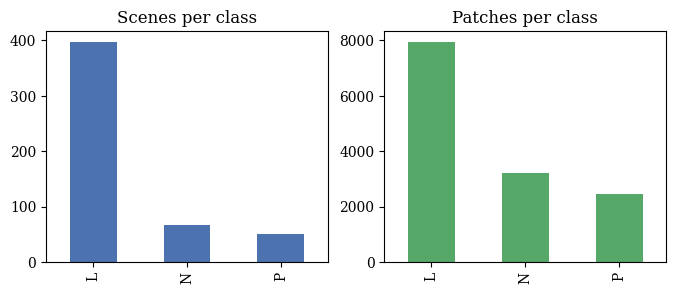

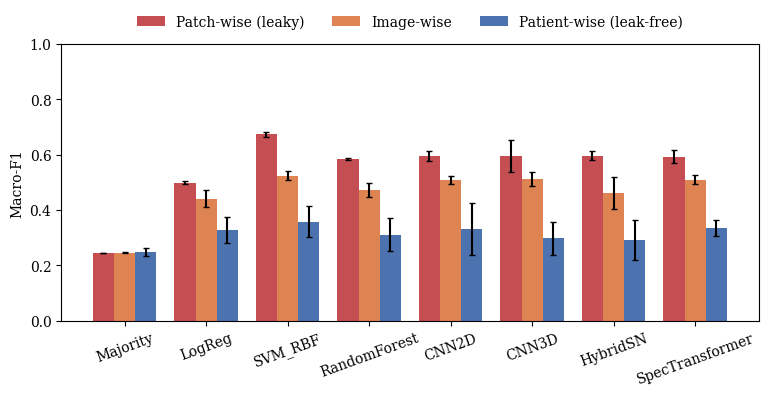

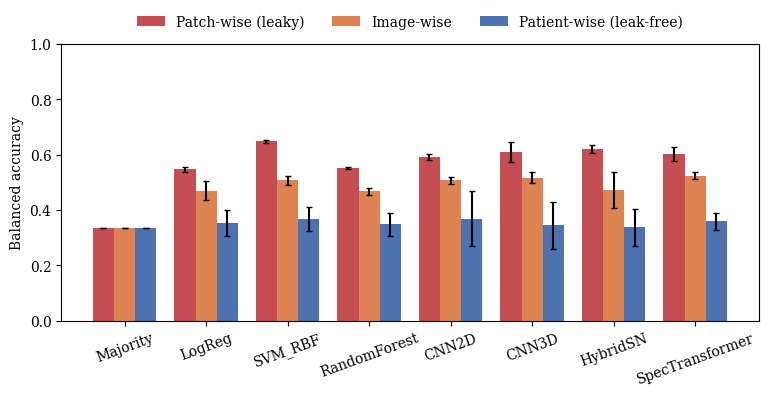

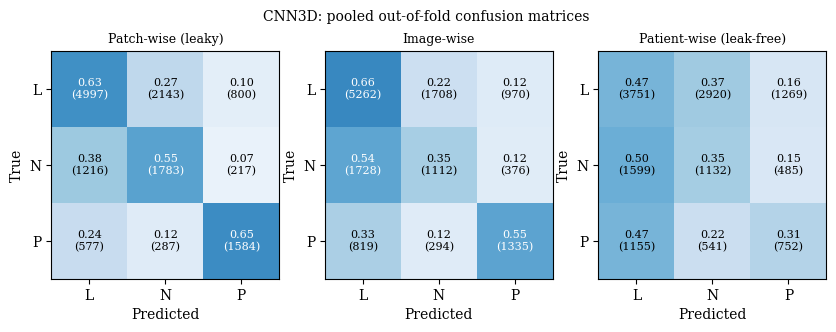

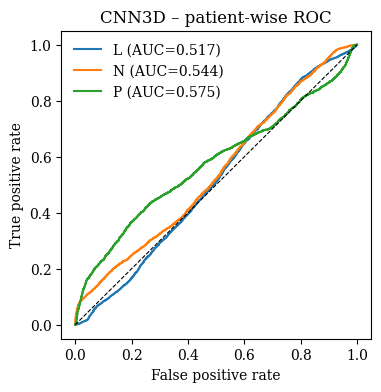

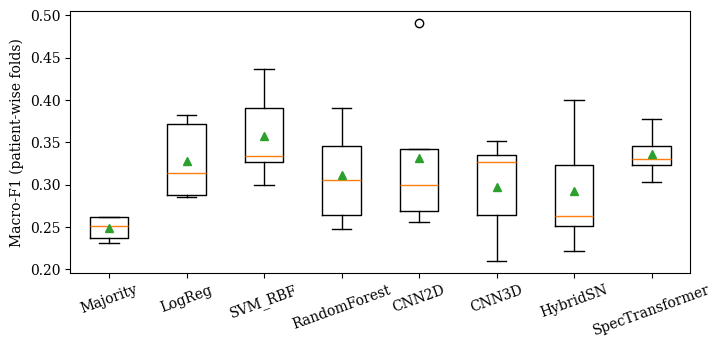

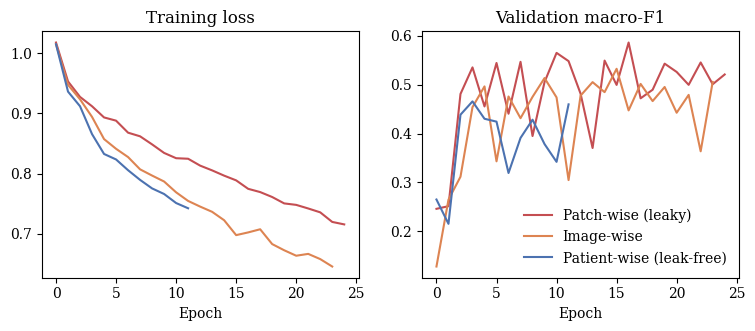

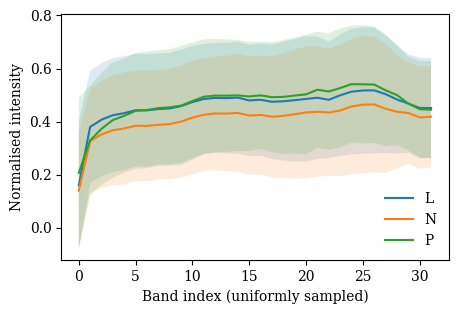

In [ ]:
# =====================================================================
# 9. FIGURES (300 dpi, paper-ready)
# =====================================================================
plt.rcParams.update({"font.size": 10, "font.family": "serif", "savefig.dpi": 300, "savefig.bbox": "tight"})
FIG = OUT / "figures"
EXP_LABEL = {"E1_PatchWise": "Patch-wise (leaky)", "E2_ImageWise": "Image-wise", "E3_PatientWise": "Patient-wise (leak-free)"}
EXP_COLOR = {"E1_PatchWise": "#c44e52", "E2_ImageWise": "#dd8452", "E3_PatientWise": "#4c72b0"}

# Fig 1: dataset composition
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
dataset_summary["scenes"].plot.bar(ax=ax[0], color="#4c72b0"); ax[0].set_title("Scenes per class"); ax[0].set_xlabel("")
meta.label.value_counts().reindex(CLASSES).plot.bar(ax=ax[1], color="#55a868"); ax[1].set_title("Patches per class"); ax[1].set_xlabel("")
fig.savefig(FIG / "Fig1_dataset_composition.png"); plt.show()

# Fig 2: leakage effect, macro-F1 & balanced accuracy, mean ± SD
for met, name in (("macro_f1", "Macro-F1"), ("balanced_accuracy", "Balanced accuracy")):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    w = 0.26
    xs = np.arange(len(ALL_MODELS))
    for j, e in enumerate(EXPERIMENTS):
        mu = [summary.loc[(e, m), (met, "mean")] for m in ALL_MODELS]
        sd = [summary.loc[(e, m), (met, "std")] for m in ALL_MODELS]
        ax.bar(xs + (j - 1) * w, mu, w, yerr=sd, capsize=2, label=EXP_LABEL[e], color=EXP_COLOR[e])
    ax.set_xticks(xs); ax.set_xticklabels(ALL_MODELS, rotation=20); ax.set_ylabel(name); ax.set_ylim(0, 1)
    ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.15))
    fig.savefig(FIG / f"Fig2_leakage_{met}.png"); plt.show()

# Fig 3: confusion matrices (pooled OOF), best E3 model under each protocol
best = pooled_df[(pooled_df.experiment == "E3_PatientWise") & (pooled_df.model != "Majority")] \
    .sort_values("macro_f1", ascending=False).model.iloc[0]
fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
for a, e in zip(ax, EXPERIMENTS):
    cm = pd.read_csv(OUT / "runs" / f"cm_{e}__{best}.csv", index_col=0).values
    cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            a.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                   color="white" if cmn[i, j] > 0.5 else "black")
    a.set_xticks(range(3)); a.set_xticklabels(CLASSES); a.set_yticks(range(3)); a.set_yticklabels(CLASSES)
    a.set_title(EXP_LABEL[e], fontsize=9); a.set_xlabel("Predicted"); a.set_ylabel("True")
fig.suptitle(f"{best}: pooled out-of-fold confusion matrices", fontsize=10)
fig.savefig(FIG / "Fig3_confusion_matrices.png"); plt.show()

# Fig 4: one-vs-rest ROC, best model, patient-wise
idx, prob = pooled("E3_PatientWise", best)
fig, ax = plt.subplots(figsize=(4, 4))
for c, name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y[idx] == c, prob[:, c])
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"{best} – patient-wise ROC"); ax.legend(frameon=False)
fig.savefig(FIG / "Fig4_roc_patientwise.png"); plt.show()

# Fig 5: per-fold macro-F1 spread under the leak-free protocol
fig, ax = plt.subplots(figsize=(8, 3.4))
data = [res_df[(res_df.experiment == "E3_PatientWise") & (res_df.model == m)].macro_f1.values for m in ALL_MODELS]
ax.boxplot(data, showmeans=True)
ax.set_xticks(range(1, len(ALL_MODELS) + 1)); ax.set_xticklabels(ALL_MODELS, rotation=20)
ax.set_ylabel("Macro-F1 (patient-wise folds)")
fig.savefig(FIG / "Fig5_patientwise_fold_spread.png"); plt.show()

# Fig 6: learning curves of the best DL model (fold 0, all protocols)
if RUN_DL and best in DL_MODELS:
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    for e in EXPERIMENTS:
        h = pd.read_csv(OUT / "runs" / f"{e}__{best}__fold0_history.csv")
        ax[0].plot(h.epoch, h.loss, label=EXP_LABEL[e], color=EXP_COLOR[e])
        ax[1].plot(h.epoch, h.val_macro_f1, label=EXP_LABEL[e], color=EXP_COLOR[e])
    ax[0].set_title("Training loss"); ax[1].set_title("Validation macro-F1")
    for a in ax: a.set_xlabel("Epoch")
    ax[1].legend(frameon=False)
    fig.savefig(FIG / "Fig6_learning_curves.png"); plt.show()

# Fig 7: mean spectral signature per class (normalised)
fig, ax = plt.subplots(figsize=(5, 3.2))
sub = np.random.default_rng(SEED).choice(len(Y), min(6000, len(Y)), replace=False)
spec = np.asarray(X[np.sort(sub)], dtype=np.float32).mean((1, 2))
ys = Y[np.sort(sub)]
for c, name in enumerate(CLASSES):
    mu, sd = spec[ys == c].mean(0), spec[ys == c].std(0)
    ax.plot(mu, label=name); ax.fill_between(range(len(mu)), mu - sd, mu + sd, alpha=0.15)
ax.set_xlabel("Band index (uniformly sampled)"); ax.set_ylabel("Normalised intensity"); ax.legend(frameon=False)
fig.savefig(FIG / "Fig7_mean_spectra.png"); plt.show()

In [ ]:
# =====================================================================
# 10. PACKAGE RESULTS
# =====================================================================
config = dict(SEED=SEED, NORM_MODE=NORM_MODE, PATCH=PATCH, N_BANDS=N_BANDS, PATCHES_PER_SCENE=PATCHES_PER_SCENE, N_FOLDS=N_FOLDS,
              EXPERIMENTS=EXPERIMENTS, MODELS=ALL_MODELS, BATCH=BATCH, EPOCHS=EPOCHS, PATIENCE=PATIENCE, LR=LR,
              BG_MEAN_MAX=BG_MEAN_MAX, MIN_PATCH_STD=MIN_PATCH_STD, EXCLUDE_PATTERNS=EXCLUDE_PATTERNS,
              n_scenes=int(meta.scene_id.nunique()), n_patients=int(meta.patient.nunique()), n_patches=int(len(Y)),
              versions=dict(numpy=np.__version__, pandas=pd.__version__,
                            tensorflow=(tf.__version__ if RUN_DL else None)))
(OUT / "config.json").write_text(json.dumps(config, indent=1, default=str))

zip_base = str(OUT) + "_Results"
# patch cache is large and reproducible from the code, so it is left out of the zip
tmp = Path(str(OUT) + "_zipstage")
if tmp.exists(): shutil.rmtree(tmp)
shutil.copytree(OUT, tmp, ignore=shutil.ignore_patterns("X_patches_*.npy"))
shutil.make_archive(zip_base, "zip", tmp); shutil.rmtree(tmp)
print("Download:", zip_base + ".zip")
print("\nReport E3_PatientWise as the primary result; E1/E2 quantify leakage inflation.")

Download: /kaggle/working/R1v2_Leakage_Aware_HSI/norm_global_Results.zip

Report E3_PatientWise as the primary result; E1/E2 quantify leakage inflation.
